# Audience Lab : préparation des données de la Google Merchandise Store

**Module** : Visualisation de Données avec Python, Master 1 Intelligence Artificielle, Université Aube-Nouvelle
**Auteur** : Abdoul-Aziz ZOROM
**Enseignant** : Dr. Zakaria Sawadogo
**Date** : 19 octobre 2026

## Contexte

Ce notebook constitue l'**étape 1 (pré-traitement)** et l'**étape 2 (indicateurs clés)** du projet « Plateforme d'Analyse et de Visualisation d'Audience Média ».
L'idée directrice est de traiter le trafic d'une boutique en ligne réelle comme l'audience d'un média, autour de quatre questions :

1. **Quand** les visiteurs viennent-ils ? (saisonnalité, heures de pointe)
2. **D'où et sur quel appareil** ?
3. **À quel point s'engagent-ils** ? (durée de session, actions, valeur du panier)
4. **Où les perd-on** ? (entonnoir `add_to_cart`, `begin_checkout`, `purchase`)

Le notebook part des trois fichiers bruts, documente chaque décision de nettoyage, construit une table **une ligne par session**, calcule les KPI, produit les figures du rapport et exporte deux fichiers Parquet légers consommés par l'application Streamlit.

## Source et licence

- **Origine** : Google Merchandise Store (boutique officielle de produits dérivés Google), sous-ensemble des données Google Analytics 4 du jeu public BigQuery `ga4_obfuscated_sample_ecommerce`, publié par Google comme jeu de démonstration.
- **Diffusion utilisée** : Observable (`@observablehq/google-merchandise-sales-data`), repris sur Kaggle (`mexwell/google-merchandise-sales-data`, licence indiquée « Other », renvoyant à la source Observable). Les fichiers sont téléchargés par `scripts/telecharger_donnees.py`.
- **Usage** : jeu de démonstration diffusé publiquement par Google, utilisé ici à des fins pédagogiques non commerciales, source citée. Les identifiants utilisateurs sont **obfusqués** par Google (aucune donnée personnelle).
- **Période** : du 1er novembre 2020 au 31 janvier 2021 (Black Friday, Noël et creux de janvier).

**Convention de langue** : les valeurs des données restent dans leur langue d'origine (`desktop`, `mobile`, `add_to_cart`, `Apparel`, codes pays...). Seuls les titres, libellés et commentaires sont en français.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pycountry
import seaborn as sns

# Racine du dépôt : le notebook s'exécute depuis notebooks/, on remonte jusqu'à trouver data/raw.
RACINE = Path.cwd().resolve()
while not (RACINE / "data" / "raw").is_dir():
    if RACINE.parent == RACINE:
        raise FileNotFoundError("Dossier data/raw introuvable : lancer le notebook depuis le dépôt.")
    RACINE = RACINE.parent

DOSSIER_BRUT = RACINE / "data" / "raw"
DOSSIER_TRAITE = RACINE / "data" / "processed"
DOSSIER_FIGURES = RACINE / "rapport" / "figures"
DOSSIER_TRAITE.mkdir(parents=True, exist_ok=True)
DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)

# Style graphique sobre et cohérent pour toutes les figures (couleurs du thème clair de l'application).
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.titleweight": "bold"})
COULEURS_APPAREILS = {"desktop": "#4F46E5", "mobile": "#0EA5E9", "tablet": "#F59E0B"}
ORDRE_APPAREILS = ["desktop", "mobile", "tablet"]
JOURS_FR = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
CADRATIN = chr(0x2014)  # caractère interdit dans tout le projet (vérifié avant export)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)


def nombre_fr(valeur, decimales=0):
    """Formate un nombre à la française : espace pour les milliers, virgule décimale."""
    return f"{valeur:,.{decimales}f}".replace(",", " ").replace(".", ",")


def pct_fr(proportion, decimales=1):
    """Formate une proportion (0 à 1) en pourcentage à la française, ex. 0.2456 -> '24,6 %'."""
    return f"{nombre_fr(proportion * 100, decimales)} %"


FORMAT_MILLIERS = plt.FuncFormatter(lambda x, _: nombre_fr(x))
FORMAT_KILO = plt.FuncFormatter(lambda x, _: f"{nombre_fr(x / 1000)} k")


def enregistrer(fig, nom):
    """Enregistre une figure du rapport en PNG haute résolution (dpi=200)."""
    chemin = DOSSIER_FIGURES / nom
    fig.savefig(chemin, dpi=200)
    print(f"Figure enregistrée : rapport/figures/{nom}")


print("pandas", pd.__version__, "| seaborn", sns.__version__, "| racine :", RACINE.name)

pandas 3.0.6 | seaborn 0.13.2 | racine : projet_visualisation_donnees


## 1. Chargement et inspection des trois fichiers

Le jeu se compose de trois tables :

| Fichier | Contenu | Clé |
|---|---|---|
| `events.csv` | un événement e-commerce GA4 par ligne (ajout au panier, début de paiement, achat) | `user_id` + `ga_session_id` |
| `items.csv` | catalogue des articles (nom, marque, variante, catégorie, prix en USD) | `id` |
| `users.csv` | utilisateurs avec leur valeur vie client (`ltv`) et date de première visite | `id` |

**Point de vigilance à la lecture** : par défaut, `pd.read_csv` interprète la chaîne `"NA"` comme une valeur manquante. Or `NA` est le code ISO de la **Namibie**. On lit donc les fichiers avec `keep_default_na=False, na_values=[""]` : seules les cellules réellement vides sont considérées comme manquantes.

In [2]:
options_lecture = {"keep_default_na": False, "na_values": [""]}
events_brut = pd.read_csv(DOSSIER_BRUT / "events.csv", **options_lecture)
items = pd.read_csv(DOSSIER_BRUT / "items.csv", **options_lecture)
users = pd.read_csv(DOSSIER_BRUT / "users.csv", **options_lecture)

for nom, table in [("events", events_brut), ("items", items), ("users", users)]:
    print(f"{nom:<7}: {table.shape[0]:>7,} lignes x {table.shape[1]} colonnes".replace(",", " "))

events : 758 884 lignes x 7 colonnes
items  :   1 381 lignes x 6 colonnes
users  : 270 154 lignes x 3 colonnes


### 1.1 Table `events`

Structure, types, aperçu et statistiques descriptives. La colonne `date` contient en réalité un **horodatage à la seconde** stocké sous forme de texte : elle sera convertie plus bas.

In [3]:
events_brut.info()

<class 'pandas.DataFrame'>
RangeIndex: 758884 entries, 0 to 758883
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   user_id        758884 non-null  int64
 1   ga_session_id  758884 non-null  int64
 2   country        754329 non-null  str  
 3   device         758884 non-null  str  
 4   type           758884 non-null  str  
 5   item_id        758884 non-null  int64
 6   date           758884 non-null  str  
dtypes: int64(3), str(4)
memory usage: 68.7 MB


In [4]:
events_brut.head()

,user_id,ga_session_id,country,device,type,item_id,date
0,2133,16909,US,mobile,purchase,94,2020-11-01 00:27:14
1,2133,16909,US,mobile,purchase,425,2020-11-01 00:27:14
2,5789,16908,SE,desktop,purchase,1,2020-11-01 01:44:44
3,5789,16908,SE,desktop,purchase,62,2020-11-01 01:44:44
4,5808,4267,US,mobile,add_to_cart,842,2020-11-01 03:06:29


In [5]:
events_brut.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,758884.0,NaN,NaN,NaN,29541.809665,55129.337846,1.0,8401.0,17181.0,25809.0,270145.0
ga_session_id,758884.0,NaN,NaN,NaN,3632.325492,3952.875337,0.0,625.0,2103.0,5365.0,18033.0
country,754329,108,US,337513,NaN,NaN,NaN,NaN,NaN,NaN,NaN
device,758884,3,desktop,441521,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,758884,3,add_to_cart,667282,NaN,NaN,NaN,NaN,NaN,NaN,NaN
item_id,758884.0,NaN,NaN,NaN,885.629356,289.267126,0.0,913.0,972.0,1040.0,1380.0
date,758884,78040,2020-11-19 21:49:59,132,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Cardinalités : nombre de valeurs distinctes par colonne
events_brut.nunique().to_frame("valeurs distinctes")

,valeurs distinctes
user_id,14701
ga_session_id,18034
country,108
device,3
type,3
item_id,1381
date,78040


In [7]:
# Modalités des deux variables catégorielles principales (valeurs conservées en anglais)
print(events_brut["device"].value_counts().to_string(), end="\n\n")
print(events_brut["type"].value_counts().to_string())

device
desktop    441521
mobile     300628
tablet      16735

type
add_to_cart       667282
begin_checkout     76047
purchase           15555


### 1.2 Tables `items` et `users`

In [8]:
items.info()
items.head()

<class 'pandas.DataFrame'>
RangeIndex: 1381 entries, 0 to 1380
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id            1381 non-null   int64
 1   name          1381 non-null   str  
 2   brand         1381 non-null   str  
 3   variant       973 non-null    str  
 4   category      1381 non-null   str  
 5   price_in_usd  1381 non-null   int64
dtypes: int64(2), str(4)
memory usage: 130.6 KB


,id,name,brand,variant,category,price_in_usd
0,0,Google Land & Sea Cotton Cap,Google,Single Option Only,Apparel,14
1,1,Google KeepCup,Google,Single Option Only,New,28
2,2,Google Land & Sea Nalgene Water Bottle,Google,Single Option Only,Drinkware,20
3,3,Google Unisex Eco Tee Black,Google,LG,Uncategorized Items,22
4,4,Google Chicago Campus Bottle,Google,Single Option Only,Campus Collection,11


In [9]:
items.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,1381.0,NaN,NaN,NaN,690.0,398.804672,0.0,345.0,690.0,1035.0,1380.0
name,1381,421,Google Land & Sea French Terry Sweatshirt,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,1381,5,Google,1166,NaN,NaN,NaN,NaN,NaN,NaN,NaN
variant,973,44,Single Option Only,263,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,1381,21,Apparel,582,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price_in_usd,1381.0,NaN,NaN,NaN,26.322954,23.283663,1.0,13.0,20.0,32.0,313.0


In [10]:
users.info()
users.describe()

<class 'pandas.DataFrame'>
RangeIndex: 270154 entries, 0 to 270153
Data columns (total 3 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   id      270154 non-null  int64
 1   ltv     270154 non-null  int64
 2   date    270154 non-null  str  
dtypes: int64(2), str(1)
memory usage: 11.1 MB


,id,ltv
count,270154.000000,270154.000000
mean,135076.500000,1.508865
std,77986.886649,19.768717
min,0.000000,0.000000
25%,67538.250000,0.000000
50%,135076.500000,0.000000
75%,202614.750000,0.000000
max,270153.000000,3360.000000


In [11]:
part_ltv = (users["ltv"] > 0).mean()
utilisateurs_events = events_brut["user_id"].unique()
print(f"Utilisateurs avec ltv > 0 : {nombre_fr((users['ltv'] > 0).sum())} sur {nombre_fr(len(users))} ({pct_fr(part_ltv)})")
print(f"ltv maximale : {nombre_fr(users['ltv'].max())} USD")
print(f"Utilisateurs des événements présents dans users.csv : "
      f"{pct_fr(np.isin(utilisateurs_events, users['id']).mean())}")

Utilisateurs avec ltv > 0 : 4 445 sur 270 154 (1,6 %)
ltv maximale : 3 360 USD
Utilisateurs des événements présents dans users.csv : 100,0 %


**Lecture.** Les trois tables sont propres sur le plan structurel : identifiants entiers, prix entiers en USD, aucune valeur manquante dans `users`.
- `users.csv` décrit **270 154 utilisateurs**, mais seuls **4 445 (1,6 %)** ont une valeur vie client (`ltv`) positive, avec un maximum de **3 360 USD** : la `ltv` est donc une variable extrêmement concentrée, typique du e-commerce (une petite minorité de clients fait l'essentiel de la valeur).
- **100 %** des utilisateurs présents dans les événements se retrouvent dans `users.csv` : la table est cohérente.
- `users.csv` n'est pas exportée dans les données traitées : l'application raisonne en sessions et en événements, et la `ltv` (cumulée sur toute la vie du client, hors de notre période) ne se filtre pas par date. Elle est mentionnée ici pour compléter l'inventaire du jeu de données.

## 2. Valeurs manquantes

On compte les valeurs manquantes par colonne, en effectif et en pourcentage, pour les trois tables.

In [12]:
def bilan_manquants(table):
    """Effectif et pourcentage de valeurs manquantes par colonne."""
    manquants = table.isna().sum()
    return pd.DataFrame({"manquants": manquants,
                         "pourcentage": (manquants / len(table) * 100).round(2)})

bilan_manquants(events_brut)

,manquants,pourcentage
user_id,0,0.0
ga_session_id,0,0.0
country,4555,0.6
device,0,0.0
type,0,0.0
item_id,0,0.0
date,0,0.0


In [13]:
print("items, variant manquant :", items["variant"].isna().sum(), "articles")
print("users, valeurs manquantes :", users.isna().sum().sum())

items, variant manquant : 408 articles
users, valeurs manquantes : 0


In [14]:
# Les valeurs manquantes de country concernent-elles des sessions entières ou des événements isolés ?
cle_brute = events_brut["user_id"].astype(str) + "_" + events_brut["ga_session_id"].astype(str)
part_par_session = events_brut["country"].isna().groupby(cle_brute).mean()
print("Sessions entièrement sans pays :", (part_par_session == 1).sum())
print("Sessions partiellement sans pays :", ((part_par_session > 0) & (part_par_session < 1)).sum())

Sessions entièrement sans pays : 136
Sessions partiellement sans pays : 0


**Décision : remplacer `country` manquant par `"(not set)"`.**
- Seule la colonne `country` présente des manquants : **4 555 événements (0,6 %)**. Ils correspondent à **136 sessions entièrement sans pays** et à **aucune** session partiellement renseignée : il s'agit d'un échec de géolocalisation au niveau de la visite, pas d'une erreur de saisie isolée.
- `"(not set)"` est la convention de Google Analytics elle-même pour une dimension non renseignée : on reste fidèle à la source et la modalité reste visible (et filtrable) dans l'application.
- **Supprimer** ces lignes ferait perdre 136 sessions réelles (leurs ajouts au panier et leurs achats) pour une seule dimension manquante ; **imputer** un pays (par exemple le plus fréquent, `US`) inventerait une information et biaiserait la carte.
- Dans `items`, la colonne `variant` a 408 valeurs manquantes (articles sans taille ni déclinaison) ; elle n'est pas utilisée dans l'analyse et n'est donc pas conservée.

In [15]:
events = events_brut.copy()
events["country"] = events["country"].fillna("(not set)")
print("Valeurs manquantes restantes dans country :", events["country"].isna().sum())
print("Événements en '(not set)' :", (events["country"] == "(not set)").sum())

Valeurs manquantes restantes dans country : 0
Événements en '(not set)' : 4555


## 3. Doublons

Un doublon exact est une ligne identique sur **les sept colonnes** : même utilisateur, même session, même pays, même appareil, même type d'événement, même article et **même horodatage à la seconde**.

In [16]:
n_avant = len(events)
n_doublons = events.duplicated().sum()
print(f"Lignes avant : {n_avant:,}".replace(",", " "))
print(f"Doublons exacts : {nombre_fr(n_doublons)} ({pct_fr(n_doublons / n_avant, 2)})")
print("Répartition des doublons par type d'événement :")
print(events.loc[events.duplicated(), "type"].value_counts().to_string())

Lignes avant : 758 884
Doublons exacts : 39 498 (5,20 %)
Répartition des doublons par type d'événement :


type
begin_checkout    37443
add_to_cart        1211
purchase            844


In [17]:
# Exemple : un même article enregistré plusieurs fois à la même seconde
exemple = events[events.duplicated(keep=False)].head(6)
exemple

,user_id,ga_session_id,country,device,type,item_id,date
13700,20939,16135,IT,desktop,purchase,526,2020-11-18 12:20:09
13701,20939,16135,IT,desktop,purchase,118,2020-11-18 12:20:09
13702,20939,16135,IT,desktop,purchase,526,2020-11-18 12:20:09
13703,20939,16135,IT,desktop,purchase,118,2020-11-18 12:20:09
14058,4497,4644,US,mobile,purchase,9,2020-11-18 14:55:50
14059,4497,4644,US,mobile,purchase,213,2020-11-18 14:55:50


**Décision : supprimer les doublons exacts.**
- **39 498 lignes (5,20 %)** sont des copies exactes d'une autre ligne. Elles concernent à **94,8 %** l'événement `begin_checkout` (37 443 lignes), puis `add_to_cart` (1 211) et `purchase` (844).
- Deux événements identiques **à la seconde près**, pour le même article dans la même session, correspondent à des envois répétés du marqueur Google Analytics (rechargement de la page de paiement, double envoi) et non à deux actions distinctes de l'utilisateur.
- Les garder gonflerait le nombre d'événements et, pour `purchase`, **compterait deux fois le même chiffre d'affaires**.
- Limite assumée : deux ajouts réellement distincts du même article dans la même seconde seraient indiscernables ; ce cas est jugé négligeable.

In [18]:
events = events.drop_duplicates().reset_index(drop=True)
n_apres = len(events)
print(f"Lignes après suppression : {n_apres:,} (-{n_avant - n_apres:,})".replace(",", " "))
assert events.duplicated().sum() == 0

Lignes après suppression : 719 386 (-39 498)


## 4. Conversion des dates et indexation temporelle

La colonne `date` est convertie en `datetime` avec `pd.to_datetime` et renommée `timestamp` (le nom `date` est réservé au jour, sans l'heure). On vérifie ensuite que la période couverte correspond bien à la documentation.

In [19]:
events["timestamp"] = pd.to_datetime(events["date"], format="%Y-%m-%d %H:%M:%S").astype("datetime64[ns]")
events = events.drop(columns="date")
print(events["timestamp"].dtype)
print("Premier événement :", events["timestamp"].min())
print("Dernier événement :", events["timestamp"].max())

datetime64[ns]
Premier événement : 2020-11-01 00:27:14
Dernier événement : 2021-01-31 23:59:08


**Indexation temporelle** : en plaçant `timestamp` en index (`set_index`), Pandas permet d'agréger par période avec `resample`. Ici, `resample("D").size()` compte les événements par jour, puis `df.plot()` trace la série.

count       92.0
mean      7819.0
std       6973.0
min         56.0
25%       3056.0
50%       6016.0
75%      11764.0
max      26742.0


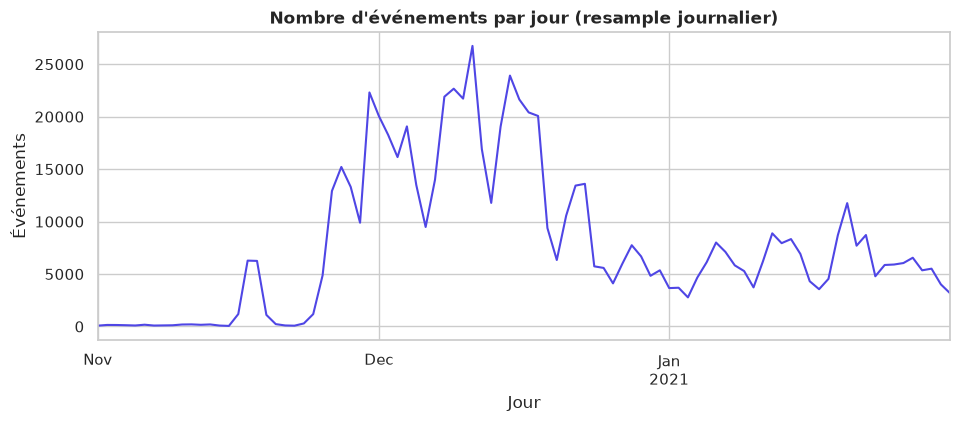

In [20]:
evenements_par_jour = events.set_index("timestamp").resample("D").size()
print(evenements_par_jour.describe().round(0).to_string())

evenements_par_jour.plot(figsize=(11, 4), color="#4F46E5")
plt.title("Nombre d'événements par jour (resample journalier)")
plt.xlabel("Jour")
plt.ylabel("Événements")
plt.grid(True)
plt.show()

In [21]:
# Même mécanique à la semaine (semaines du lundi au dimanche, étiquetées par leur lundi :
# la première, celle du 26 octobre, ne contient que le dimanche 1er novembre) et au mois
print(events.set_index("timestamp").resample("W-MON", label="left", closed="left").size().head().to_string())
print()
print(events.set_index("timestamp").resample("MS").size().rename("événements").to_string())

timestamp
2020-10-26       81
2020-11-02      876
2020-11-09     1014
2020-11-16    15224
2020-11-23    57668
Freq: W-MON

timestamp
2020-11-01     97170
2020-12-01    436620
2021-01-01    185596
Freq: MS


**Lecture.** La période couvre bien du **2020-11-01 00:27:14** au **2021-01-31 23:59:08** (92 jours). Le volume quotidien est très variable : de **56** à **26 742** événements par jour (moyenne 7 819). Décembre concentre à lui seul **436 620 événements, soit 60,7 %** du total, contre 97 170 en novembre et 185 596 en janvier : la saisonnalité de fin d'année domine le jeu de données. L'analyse fine de la courbe est faite plus bas au niveau des sessions.

## 5. Enrichissement : jointure avec le catalogue et noms de pays

### 5.1 Jointure `items`

Chaque événement porte un `item_id`. On joint le catalogue (préfixe `item_` pour éviter toute collision de noms) avec une **jointure à gauche** : aucune ligne d'événement ne doit être perdue ni dupliquée. Le paramètre `validate="many_to_one"` garantit que chaque article n'apparaît qu'une fois dans le catalogue.

In [22]:
catalogue = items.add_prefix("item_")  # id -> item_id, name -> item_name, ...
n_avant_jointure = len(events)
events = events.merge(catalogue, on="item_id", how="left", validate="many_to_one", indicator=True)

print("Lignes avant / après jointure :", n_avant_jointure, "/", len(events))
print(events["_merge"].value_counts().to_string())
assert len(events) == n_avant_jointure
assert (events["_merge"] == "both").all(), "Des articles sont absents du catalogue"
events = events.drop(columns="_merge")
events["price_in_usd"] = events.pop("item_price_in_usd").astype("float64")
events[["item_id", "item_name", "item_category", "item_brand", "price_in_usd"]].head()

Lignes avant / après jointure : 719386 / 719386
_merge
both          719386
left_only          0
right_only         0


,item_id,item_name,item_category,item_brand,price_in_usd
0,94,Google Large Tote White,Bags,Google,10.0
1,425,Google Heather Green Speckled Tee,Apparel,Google,21.0
2,1,Google KeepCup,New,Google,28.0
3,62,Google Mini Kick Ball,Fun,Google,2.0
4,842,Google Infant Hero Onesie Grey,Apparel,Google,25.0


### 5.2 Noms de pays avec `pycountry`

Les pays sont des codes ISO alpha-2 (`US`, `IN`...). On ajoute le code **ISO alpha-3** (utile pour la carte choroplèthe de l'application) et le **nom anglais** du pays (valeur de donnée, non traduite). Règles :

- on préfère le nom usuel (`common_name`, ex. « Taiwan », « Bolivia ») au nom officiel quand pycountry le fournit ;
- `(not set)` est conservé tel quel, avec un code ISO-3 vide (`None`) ;
- `XK` (Kosovo) n'est pas un code ISO 3166 officiel : il est complété à la main (`XKX`, « Kosovo »), convention utilisée par l'Union européenne et la Banque mondiale.

In [23]:
COMPLEMENTS_PAYS = {"XK": ("XKX", "Kosovo")}


def decrire_pays(code_iso2):
    """Renvoie (code ISO alpha-3, nom anglais) pour un code alpha-2."""
    if code_iso2 == "(not set)":
        return None, "(not set)"
    if code_iso2 in COMPLEMENTS_PAYS:
        return COMPLEMENTS_PAYS[code_iso2]
    pays = pycountry.countries.get(alpha_2=code_iso2)
    if pays is None:
        return None, code_iso2
    nom = getattr(pays, "common_name", pays.name).replace(CADRATIN, "-")
    return pays.alpha_3, nom


codes_pays = sorted(events["country"].unique())
table_pays = pd.DataFrame([(c, *decrire_pays(c)) for c in codes_pays],
                          columns=["country", "country_iso3", "country_name"])
print("Pays distincts (hors '(not set)') :", (table_pays["country"] != "(not set)").sum())
print("Codes sans correspondance ISO-3 :", table_pays.loc[table_pays["country_iso3"].isna(), "country"].tolist())
table_pays.sample(8, random_state=1)

Pays distincts (hors '(not set)') : 108
Codes sans correspondance ISO-3 : ['(not set)']


,country,country_iso3,country_name
100,TT,TTO,Trinidad and Tobago
90,RU,RUS,Russian Federation
92,SE,SWE,Sweden
89,RS,SRB,Serbia
101,TW,TWN,Taiwan
55,KH,KHM,Cambodia
88,RO,ROU,Romania
54,KE,KEN,Kenya


In [24]:
events = events.merge(table_pays, on="country", how="left", validate="many_to_one")
assert events["country_name"].notna().all()
events.loc[events["country"] != "(not set)", ["country", "country_iso3", "country_name"]].drop_duplicates().head()

,country,country_iso3,country_name
0,US,USA,United States
2,SE,SWE,Sweden
52,CA,CAN,Canada
57,BE,BEL,Belgium
61,GB,GBR,United Kingdom


## 6. Variables dérivées au niveau événement

À partir de l'horodatage on dérive :

- `date` : le jour (minuit), pour les agrégations quotidiennes ;
- `hour` : l'heure (0 à 23) ;
- `weekday` : le jour de la semaine, codé **0 = lundi** à 6 = dimanche (les libellés français `Lundi`...`Dimanche` ne servent qu'à l'affichage) ;
- `month` : le mois au format `"2020-11"`.

On crée aussi la clé de session `session_key = "{user_id}_{ga_session_id}"` : `ga_session_id` seul n'est pas unique (c'est un identifiant de session **par utilisateur**).

In [25]:
events["session_key"] = events["user_id"].astype(str) + "_" + events["ga_session_id"].astype(str)
events["date"] = events["timestamp"].dt.normalize()
events["hour"] = events["timestamp"].dt.hour.astype("int64")
events["weekday"] = events["timestamp"].dt.weekday.astype("int64")
events["month"] = events["timestamp"].dt.strftime("%Y-%m")

# Ordre des colonnes de l'interface (contrat avec l'application)
COLONNES_EVENTS = ["user_id", "ga_session_id", "session_key", "country", "country_iso3", "country_name",
                   "device", "type", "item_id", "item_name", "item_category", "item_brand", "price_in_usd",
                   "timestamp", "date", "hour", "weekday", "month"]
events = events[COLONNES_EVENTS].sort_values(["timestamp", "session_key", "item_id"]).reset_index(drop=True)

print("ga_session_id distincts :", events["ga_session_id"].nunique(),
      "| sessions (user_id + ga_session_id) :", events["session_key"].nunique())
print(events["month"].value_counts().sort_index().to_string())
events.head()

ga_session_id distincts : 18034 | sessions (user_id + ga_session_id) : 18101
month
2020-11     97170
2020-12    436620
2021-01    185596


,user_id,ga_session_id,session_key,country,country_iso3,country_name,device,type,item_id,item_name,item_category,item_brand,price_in_usd,timestamp,date,hour,weekday,month
0,2133,16909,2133_16909,US,USA,United States,mobile,purchase,94,Google Large Tote White,Bags,Google,10.0,2020-11-01 00:27:14,2020-11-01,0,6,2020-11
1,2133,16909,2133_16909,US,USA,United States,mobile,purchase,425,Google Heather Green Speckled Tee,Apparel,Google,21.0,2020-11-01 00:27:14,2020-11-01,0,6,2020-11
2,5789,16908,5789_16908,SE,SWE,Sweden,desktop,purchase,1,Google KeepCup,New,Google,28.0,2020-11-01 01:44:44,2020-11-01,1,6,2020-11
3,5789,16908,5789_16908,SE,SWE,Sweden,desktop,purchase,62,Google Mini Kick Ball,Fun,Google,2.0,2020-11-01 01:44:44,2020-11-01,1,6,2020-11
4,5808,4267,5808_4267,US,USA,United States,mobile,add_to_cart,252,Android Iconic Hat Black,Clearance,Android,9.0,2020-11-01 03:06:29,2020-11-01,3,6,2020-11


## 7. Construction de la table des sessions

L'audience se mesure en **sessions** (visites). On agrège les événements par `session_key` avec `groupby(...).agg(...)` :

| Colonne | Définition |
|---|---|
| `start`, `end` | premier et dernier horodatage de la session |
| `duration_s` | `end - start` en secondes (0 si un seul horodatage) |
| `n_events` | nombre d'événements |
| `n_items` | nombre d'articles distincts |
| `cart_value_usd` | somme des prix des événements `add_to_cart` |
| `revenue_usd` | somme des prix des événements `purchase` (chiffre d'affaires) |
| `reached_checkout`, `purchased` | la session contient au moins un `begin_checkout` / un `purchase` |
| `main_category` | catégorie d'article la plus fréquente (égalité : première par ordre alphabétique) |
| `date`, `hour`, `weekday` | dérivés du **début** de session |

Le pays et l'appareil sont constants au sein d'une session (vérifié ci-dessous), on garde donc la première valeur.

In [26]:
groupes = events.groupby("session_key")
print("Appareils distincts par session (max) :", groupes["device"].nunique().max())
print("Pays distincts par session (max) :", groupes["country"].nunique().max())

Appareils distincts par session (max) : 1
Pays distincts par session (max) : 1


In [27]:
# Montants par type d'événement : colonnes auxiliaires remplies de 0 hors du type concerné
events_aux = events.assign(
    prix_panier=events["price_in_usd"].where(events["type"] == "add_to_cart", 0.0),
    prix_achat=events["price_in_usd"].where(events["type"] == "purchase", 0.0),
    est_panier=events["type"].eq("add_to_cart"),
    est_checkout=events["type"].eq("begin_checkout"),
    est_achat=events["type"].eq("purchase"),
)

sessions = events_aux.groupby("session_key").agg(
    user_id=("user_id", "first"),
    ga_session_id=("ga_session_id", "first"),
    country=("country", "first"),
    country_iso3=("country_iso3", "first"),
    country_name=("country_name", "first"),
    device=("device", "first"),
    start=("timestamp", "min"),
    end=("timestamp", "max"),
    n_events=("type", "size"),
    n_items=("item_id", "nunique"),
    cart_value_usd=("prix_panier", "sum"),
    revenue_usd=("prix_achat", "sum"),
    reached_checkout=("est_checkout", "any"),
    purchased=("est_achat", "any"),
).reset_index()

sessions["duration_s"] = (sessions["end"] - sessions["start"]).dt.total_seconds()
sessions["date"] = sessions["start"].dt.normalize()
sessions["hour"] = sessions["start"].dt.hour.astype("int64")
sessions["weekday"] = sessions["start"].dt.weekday.astype("int64")
print(f"{len(sessions):,} sessions construites".replace(",", " "))

18 101 sessions construites


In [28]:
# Catégorie principale : la plus fréquente, égalité départagée par ordre alphabétique
comptes_categories = (events.groupby(["session_key", "item_category"]).size()
                      .rename("n").reset_index()
                      .sort_values(["session_key", "n", "item_category"], ascending=[True, False, True]))
categorie_principale = comptes_categories.drop_duplicates("session_key").set_index("session_key")["item_category"]
sessions["main_category"] = sessions["session_key"].map(categorie_principale)
sessions["main_category"].value_counts().head(8)

main_category
Apparel              8786
Accessories          2301
New                  2282
Campus Collection    1030
Shop by Brand        1016
Bags                  790
Office                738
Drinkware             471
Name: count, dtype: int64

In [29]:
# Contrôles de cohérence entre la table des événements et celle des sessions
assert sessions["session_key"].is_unique
assert sessions["n_events"].sum() == len(events)
assert abs(sessions["revenue_usd"].sum() - events.loc[events["type"] == "purchase", "price_in_usd"].sum()) < 1e-6
assert (sessions["duration_s"] >= 0).all()
assert ((sessions["revenue_usd"] > 0) == sessions["purchased"]).all()
print("Contrôles de cohérence : OK")
sessions[["duration_s", "n_events", "n_items", "cart_value_usd", "revenue_usd"]].describe().T.round(1)

Contrôles de cohérence : OK


,count,mean,std,min,25%,50%,75%,max
duration_s,18101.0,341.5,700.5,0.0,0.0,66.0,364.0,16196.0
n_events,18101.0,39.7,62.1,1.0,12.0,16.0,45.0,927.0
n_items,18101.0,17.1,16.0,1.0,12.0,12.0,21.0,160.0
cart_value_usd,18101.0,938.6,1693.9,0.0,182.0,382.0,1026.0,39921.0
revenue_usd,18101.0,16.0,42.4,0.0,0.0,0.0,0.0,1026.0


In [30]:
print("Utilisateurs ayant plusieurs sessions :", (sessions.groupby("user_id").size() > 1).sum())
print("Sessions avec exactement 12 articles distincts :", (sessions["n_items"] == 12).sum(),
      f"({pct_fr((sessions['n_items'] == 12).mean())})")
print("Valeurs de panier les plus fréquentes (USD) :", sessions["cart_value_usd"].value_counts().head(4).to_dict())

Utilisateurs ayant plusieurs sessions : 2374
Sessions avec exactement 12 articles distincts : 6155 (34,0 %)
Valeurs de panier les plus fréquentes (USD) : {0.0: 2913, 191.0: 1058, 382.0: 522, 245.0: 123}


**Lecture.**
- On obtient **18 101 sessions** pour **14 701 utilisateurs** ; 2 374 utilisateurs reviennent au moins une fois. `ga_session_id` seul ne compte que 18 034 valeurs distinctes : il n'est unique qu'au sein d'un utilisateur, d'où la clé composée `session_key`.
- La durée est très asymétrique (médiane 66 s, moyenne 341,5 s, maximum 16 196 s), tout comme le nombre d'événements (médiane 16, maximum 927) : la moyenne est tirée par une queue de longues sessions, ce que la section suivante examine.
- **Artefact du jeu obfusqué** : **6 155 sessions (34,0 %)** contiennent exactement **12 articles distincts**, et les valeurs de panier 191 USD et 382 USD (= 2 x 191) reviennent très souvent. Un tel motif est peu plausible pour de vrais clients : il provient vraisemblablement de l'obfuscation appliquée par Google à cet échantillon public. On le conserve (on ne peut pas distinguer les sessions « réelles ») mais on le signale comme limite.

## 8. Valeurs aberrantes (méthode IQR)

On applique la règle de Tukey sur les deux mesures d'engagement : une valeur est **aberrante** si elle dépasse la borne haute $Q_3 + 1{,}5 \times IQR$ avec $IQR = Q_3 - Q_1$ (la borne basse est négative ou nulle, donc sans objet pour des durées et des comptages). Les bornes sont calculées sur **l'ensemble des sessions**. On regarde d'abord les boxplots avant de décider.

In [31]:
def borne_haute_iqr(serie):
    """Renvoie (Q1, Q3, IQR, borne haute Q3 + 1,5 x IQR)."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1, q3, iqr, q3 + 1.5 * iqr


bilan_iqr = []
for colonne in ["duration_s", "n_events"]:
    q1, q3, iqr, borne = borne_haute_iqr(sessions[colonne])
    au_dessus = sessions[colonne] > borne
    bilan_iqr.append({"variable": colonne, "Q1": q1, "Q3": q3, "IQR": iqr, "borne haute": borne,
                      "sessions au-dessus": int(au_dessus.sum()), "part (%)": round(au_dessus.mean() * 100, 1),
                      "maximum": sessions[colonne].max()})
bilan_iqr = pd.DataFrame(bilan_iqr).set_index("variable")
BORNE_DUREE = bilan_iqr.loc["duration_s", "borne haute"]
BORNE_EVENEMENTS = bilan_iqr.loc["n_events", "borne haute"]
bilan_iqr

,Q1,Q3,IQR,borne haute,sessions au-dessus,part (%),maximum
variable,,,,,,,
duration_s,0.0,364.0,364.0,910.0,2075,11.5,16196.0
n_events,12.0,45.0,33.0,94.5,1901,10.5,927.0


Figure enregistrée : rapport/figures/valeurs_aberrantes.png


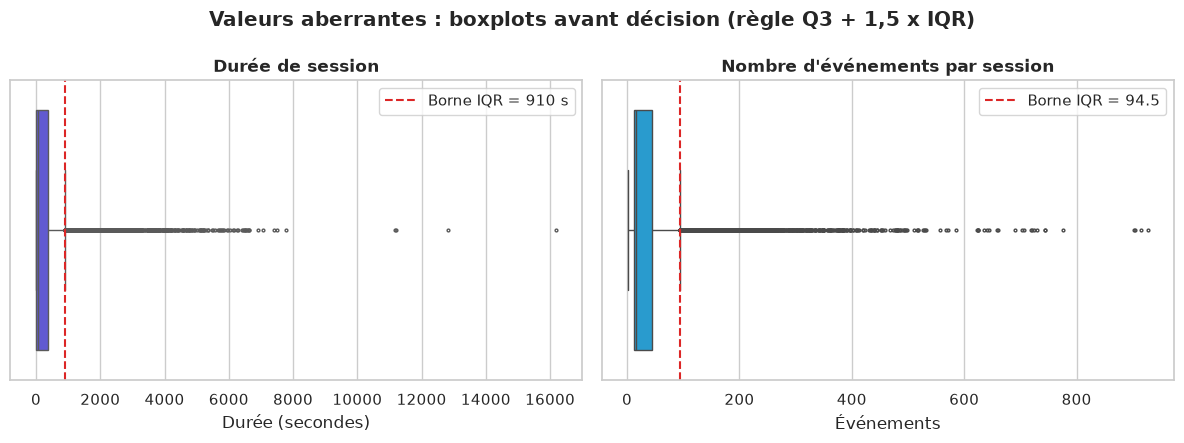

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(x=sessions["duration_s"], ax=axes[0], color="#4F46E5", fliersize=2)
axes[0].axvline(BORNE_DUREE, color="#DC2626", linestyle="--", label=f"Borne IQR = {BORNE_DUREE:.0f} s")
axes[0].set_title("Durée de session")
axes[0].set_xlabel("Durée (secondes)")
axes[0].legend()

sns.boxplot(x=sessions["n_events"], ax=axes[1], color="#0EA5E9", fliersize=2)
axes[1].axvline(BORNE_EVENEMENTS, color="#DC2626", linestyle="--", label=f"Borne IQR = {BORNE_EVENEMENTS:.1f}")
axes[1].set_title("Nombre d'événements par session")
axes[1].set_xlabel("Événements")
axes[1].legend()

fig.suptitle("Valeurs aberrantes : boxplots avant décision (règle Q3 + 1,5 x IQR)", fontweight="bold")
fig.tight_layout()
enregistrer(fig, "valeurs_aberrantes.png")
plt.show()

In [33]:
sessions["is_outlier_duration"] = sessions["duration_s"] > BORNE_DUREE
sessions["is_outlier_events"] = sessions["n_events"] > BORNE_EVENEMENTS
aberrantes = sessions["is_outlier_duration"] | sessions["is_outlier_events"]

comparaison = sessions.groupby(aberrantes).agg(
    sessions=("session_key", "size"),
    taux_achat=("purchased", "mean"),
    panier_moyen=("cart_value_usd", "mean"),
    ca_total=("revenue_usd", "sum"),
)
comparaison.index = comparaison.index.map({False: "sessions typiques", True: "au moins un indicateur aberrant"})
comparaison["part_du_ca"] = comparaison["ca_total"] / comparaison["ca_total"].sum()
print("Sessions aberrantes sur les deux critères :",
      (sessions["is_outlier_duration"] & sessions["is_outlier_events"]).sum())
comparaison.round(3)

Sessions aberrantes sur les deux critères : 976


,sessions,taux_achat,panier_moyen,ca_total,part_du_ca
sessions typiques,15101,0.201,514.327,166584.0,0.576
au moins un indicateur aberrant,3000,0.471,3074.428,122823.0,0.424


**Décision : signaler, ne pas supprimer.**
- **Durée** : Q1 = 0 s (un tiers des sessions n'ont qu'un horodatage), Q3 = 364 s, d'où une borne haute de **910 s** (environ 15 minutes) ; **2 075 sessions (11,5 %)** la dépassent, jusqu'à 16 196 s.
- **Événements** : Q1 = 12, Q3 = 45, borne haute **94,5** ; **1 901 sessions (10,5 %)** la dépassent, jusqu'à 927 événements. 976 sessions sont hors bornes sur les deux critères.
- Les boxplots montrent une **queue continue** et non quelques points isolés : ce ne sont pas des erreurs de mesure mais de vrais comportements (sessions d'achat groupé, onglet laissé ouvert, clients qui composent une grosse commande).
- Surtout, ces **3 000 sessions (16,6 %)** pèsent lourd : taux d'achat de **47,1 %** contre 20,1 % pour les sessions typiques, panier moyen de **3 074 USD** contre 514 USD, et **42,4 % du chiffre d'affaires** (122 823 USD). Les supprimer fausserait tous les indicateurs business.
- On conserve donc toutes les sessions avec deux indicateurs booléens `is_outlier_duration` et `is_outlier_events` : l'application et le rapport peuvent les isoler si besoin, et les graphiques de distribution utilisent une échelle logarithmique plutôt qu'une coupure.

## 9. Indicateurs clés (étape 2)

Indicateurs calculés sur l'ensemble de la période, **toutes sessions conservées** (y compris les sessions signalées aberrantes). Ce sont les mêmes définitions que dans l'application :

- **taux de conversion** = sessions avec au moins un `purchase` / sessions ;
- **valeur moyenne du panier par session** = moyenne de `cart_value_usd` ;
- **chiffre d'affaires** = somme des prix des événements `purchase`.

In [34]:
kpi = pd.Series({
    "Sessions": len(sessions),
    "Utilisateurs": sessions["user_id"].nunique(),
    "Événements": len(events),
    "Durée moyenne de session (s)": sessions["duration_s"].mean(),
    "Durée médiane de session (s)": sessions["duration_s"].median(),
    "Événements par session (moyenne)": sessions["n_events"].mean(),
    "Valeur moyenne du panier par session (USD)": sessions["cart_value_usd"].mean(),
    "Chiffre d'affaires total (USD)": sessions["revenue_usd"].sum(),
    "Chiffre d'affaires moyen par session (USD)": sessions["revenue_usd"].mean(),
    "Taux de passage au paiement (%)": sessions["reached_checkout"].mean() * 100,
    "Taux de conversion (%)": sessions["purchased"].mean() * 100,
    "Part des sessions mobile (%)": (sessions["device"] == "mobile").mean() * 100,
})
entiers = ["Sessions", "Utilisateurs", "Événements"]
kpi.to_frame("valeur").assign(valeur=[nombre_fr(v, 0 if k in entiers else 2) for k, v in kpi.items()])

,valeur
Sessions,18 101
Utilisateurs,14 701
Événements,719 386
Durée moyenne de session (s),"341,48"
Durée médiane de session (s),"66,00"
Événements par session (moyenne),"39,74"
Valeur moyenne du panier par session (USD),"938,63"
Chiffre d'affaires total (USD),"289 407,00"
Chiffre d'affaires moyen par session (USD),"15,99"
Taux de passage au paiement (%),"40,37"


In [35]:
repartition_appareils = sessions.groupby("device").agg(
    sessions=("session_key", "size"),
    duree_moyenne_s=("duration_s", "mean"),
    duree_mediane_s=("duration_s", "median"),
    panier_moyen_usd=("cart_value_usd", "mean"),
    taux_conversion=("purchased", "mean"),
    ca_usd=("revenue_usd", "sum"),
).reindex(ORDRE_APPAREILS)
repartition_appareils.insert(1, "part_sessions", repartition_appareils["sessions"] / len(sessions))
repartition_appareils.round(3)

,sessions,part_sessions,duree_moyenne_s,duree_mediane_s,panier_moyen_usd,taux_conversion,ca_usd
device,,,,,,,
desktop,10489,0.579,343.637,64.0,933.303,0.241,167178.0
mobile,7231,0.399,339.225,69.0,940.471,0.252,116474.0
tablet,381,0.021,324.984,69.0,1050.341,0.239,5755.0


In [36]:
repartition_categories = events_aux.groupby("item_category").agg(
    evenements=("type", "size"),
    ajouts_panier=("est_panier", "sum"),
    achats=("est_achat", "sum"),
    ca_usd=("prix_achat", "sum"),
).sort_values("evenements", ascending=False)
repartition_categories["part_evenements"] = repartition_categories["evenements"] / len(events)
repartition_categories["part_ca"] = repartition_categories["ca_usd"] / repartition_categories["ca_usd"].sum()
repartition_categories["achats_pour_100_ajouts"] = repartition_categories["achats"] / repartition_categories["ajouts_panier"] * 100
repartition_categories["prix_moyen_achat_usd"] = repartition_categories["ca_usd"] / repartition_categories["achats"]
repartition_categories.round(3)

,evenements,ajouts_panier,achats,ca_usd,part_evenements,part_ca,achats_pour_100_ajouts,prix_moyen_achat_usd
item_category,,,,,,,,
Apparel,282871,265434,4858,157235.0,0.393,0.543,1.830,32.366
New,70360,65046,1397,18506.0,0.098,0.064,2.148,13.247
Accessories,65098,60914,1173,13810.0,0.090,0.048,1.926,11.773
Shop by Brand,47725,44481,818,15049.0,0.066,0.052,1.839,18.397
Campus Collection,45724,40785,1456,15553.0,0.064,0.054,3.570,10.682
Clearance,36529,34162,633,8605.0,0.051,0.030,1.853,13.594
Lifestyle,27752,25562,583,10031.0,0.039,0.035,2.281,17.206
Bags,26720,23851,671,19137.0,0.037,0.066,2.813,28.520
Office,26291,23343,798,4501.0,0.037,0.016,3.419,5.640


In [37]:
top_pays = (sessions.groupby("country_name").size().sort_values(ascending=False)
            .head(10).rename("sessions").to_frame())
top_pays["part"] = (top_pays["sessions"] / len(sessions)).round(3)
top_pays

,sessions,part
country_name,,
United States,7993,0.442
India,1667,0.092
Canada,1408,0.078
United Kingdom,554,0.031
France,356,0.020
Spain,330,0.018
China,320,0.018
Taiwan,311,0.017
Germany,286,0.016


**Lecture des indicateurs clés.**
- **Volume** : 18 101 sessions, 14 701 utilisateurs et 719 386 événements sur trois mois.
- **Engagement** : durée moyenne **341,5 s** mais médiane **66 s** ; c'est la médiane qui décrit la session « typique », la moyenne étant tirée par les longues sessions.
- **Valeur** : la valeur moyenne ajoutée au panier atteint **938,63 USD par session**, alors que le chiffre d'affaires moyen n'est que de **15,99 USD par session** (289 407 USD au total, 65,09 USD par session acheteuse). Seulement **1,7 %** de la valeur ajoutée au panier est finalement achetée : l'abandon de panier est massif (et un même article ajouté plusieurs fois compte plusieurs fois).
- **Conversion** : **40,37 %** des sessions atteignent le paiement et **24,56 %** achètent.
- **Appareils** : desktop domine (**57,9 %** des sessions), mobile suit (**39,9 %**), tablet reste marginal (**2,1 %**). Les comportements sont remarquablement proches : taux de conversion de 24,1 % (desktop), 25,2 % (mobile) et 23,9 % (tablet), durées médianes de 64 à 69 s.
- **Catégories** : `Apparel` représente **39,3 %** des événements et **54,3 %** du chiffre d'affaires.
- **Pays** : audience très américaine (**44,2 %** des sessions aux États-Unis), suivie de l'Inde (9,2 %) et du Canada (7,8 %), sur 108 pays plus la modalité `(not set)`.

## 10. Visualisations Seaborn / Matplotlib

Les figures suivantes sont enregistrées dans `rapport/figures/` en PNG à 200 dpi pour le rapport. Elles préfigurent les graphiques interactifs Plotly de l'application.

### 10.1 Évolution temporelle du trafic

Figure enregistrée : rapport/figures/evolution_trafic.png


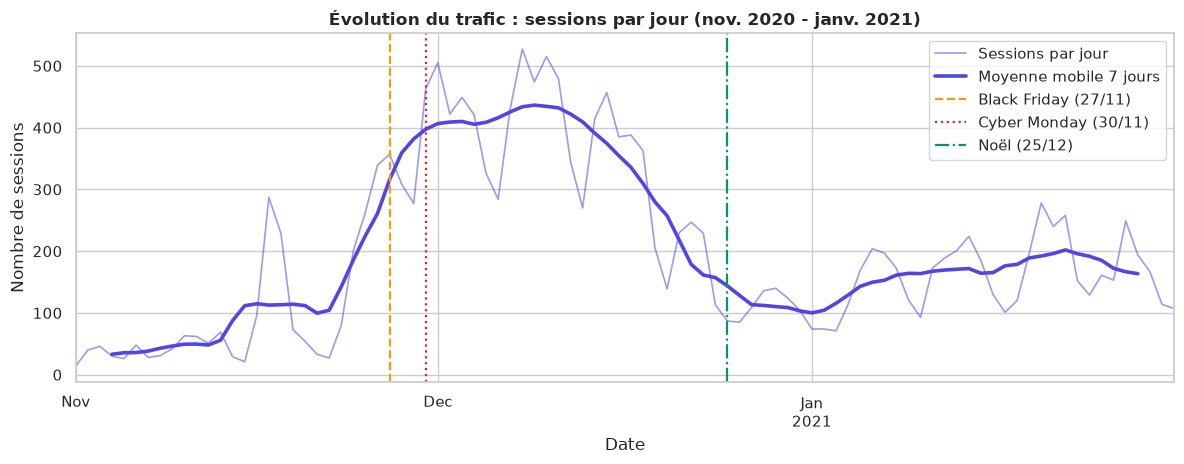

In [38]:
sessions_par_jour = sessions.set_index("start").resample("D").size()
moyenne_mobile = sessions_par_jour.rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 4.8))
sessions_par_jour.plot(ax=ax, color="#4F46E5", alpha=0.55, linewidth=1.2, label="Sessions par jour")
moyenne_mobile.plot(ax=ax, color="#4F46E5", linewidth=2.6, label="Moyenne mobile 7 jours")
# Repères calendaires tracés en lignes verticales et nommés dans la légende (aucun texte sur la courbe)
REPERES = {"2020-11-27": ("Black Friday (27/11)", "#F59E0B", "--"),
           "2020-11-30": ("Cyber Monday (30/11)", "#DC2626", ":"),
           "2020-12-25": ("Noël (25/12)", "#059669", "-.")}
for jour, (libelle, couleur, style) in REPERES.items():
    ax.axvline(pd.Timestamp(jour), color=couleur, linestyle=style, linewidth=1.6, label=libelle)
plt.title("Évolution du trafic : sessions par jour (nov. 2020 - janv. 2021)")
plt.xlabel("Date")
plt.ylabel("Nombre de sessions")
plt.grid(True)
ax.legend(loc="upper right")
fig.tight_layout()
enregistrer(fig, "evolution_trafic.png")
plt.show()

In [39]:
pic = sessions_par_jour.idxmax()
print(f"Jour record : {pic:%Y-%m-%d} ({sessions_par_jour.max()} sessions)")
print("Moyenne de sessions par jour, par mois :")
print(sessions_par_jour.groupby(sessions_par_jour.index.strftime("%Y-%m")).mean().round(1).to_string())
print("5 jours les plus actifs :")
print(sessions_par_jour.sort_values(ascending=False).head(5).to_string())
print("Démarrage de la saison :", {f"{jour:%d/%m}": int(n) for jour, n in sessions_par_jour["2020-11-22":"2020-11-24"].items()})
print("Sessions aux dates repères :", {libelle: int(sessions_par_jour[jour]) for jour, (libelle, _, _) in REPERES.items()})
sessions_par_semaine = sessions.set_index("start").resample("W-MON", label="left", closed="left").size()
print(f"Semaine la plus chargée : semaine du {sessions_par_semaine.idxmax():%Y-%m-%d} "
      f"({nombre_fr(sessions_par_semaine.max())} sessions)")
print(f"Rapport décembre / novembre (sessions par jour) : "
      f"{nombre_fr(sessions_par_jour['2020-12'].mean() / sessions_par_jour['2020-11'].mean(), 2)}")

Jour record : 2020-12-08 (527 sessions)
Moyenne de sessions par jour, par mois :
start
2020-11    122.9
2020-12    303.3
2021-01    161.6
5 jours les plus actifs :
start
2020-12-08    527
2020-12-10    515
2020-12-01    505
2020-12-11    479
2020-12-09    474
Démarrage de la saison : {'22/11': 27, '23/11': 80, '24/11': 201}
Sessions aux dates repères : {'Black Friday (27/11)': 357, 'Cyber Monday (30/11)': 463, 'Noël (25/12)': 87}
Semaine la plus chargée : semaine du 2020-12-07 (3 041 sessions)
Rapport décembre / novembre (sessions par jour) : 2,47


**Interprétation.**
- Le trafic est faible début novembre (moyenne de **122,9 sessions par jour** sur le mois), décolle à partir du **24 novembre** (201 sessions, contre 80 la veille) et culmine **début décembre** : le record est le **8 décembre 2020 (527 sessions)** et les cinq jours les plus actifs se situent tous entre le 1er et le 11 décembre. La semaine du 7 décembre totalise 3 041 sessions.
- Le Black Friday (357 sessions le 27 novembre) et le Cyber Monday (463 le 30 novembre) lancent la saison, mais **le pic est la première quinzaine de décembre**, période des commandes de Noël avant les dates limites de livraison.
- Le trafic s'effondre ensuite : **87 sessions le jour de Noël**, puis un creux autour du Nouvel An, avant une reprise modérée en janvier (moyenne de **161,6 sessions par jour**, contre **303,3** en décembre).
- Pour l'audience, la leçon est claire : la boutique fonctionne comme un média saisonnier, avec **2,47 fois** plus de visites quotidiennes en décembre qu'en novembre.

### 10.2 Comparaison des catégories de produits

Figure enregistrée : rapport/figures/categories.png


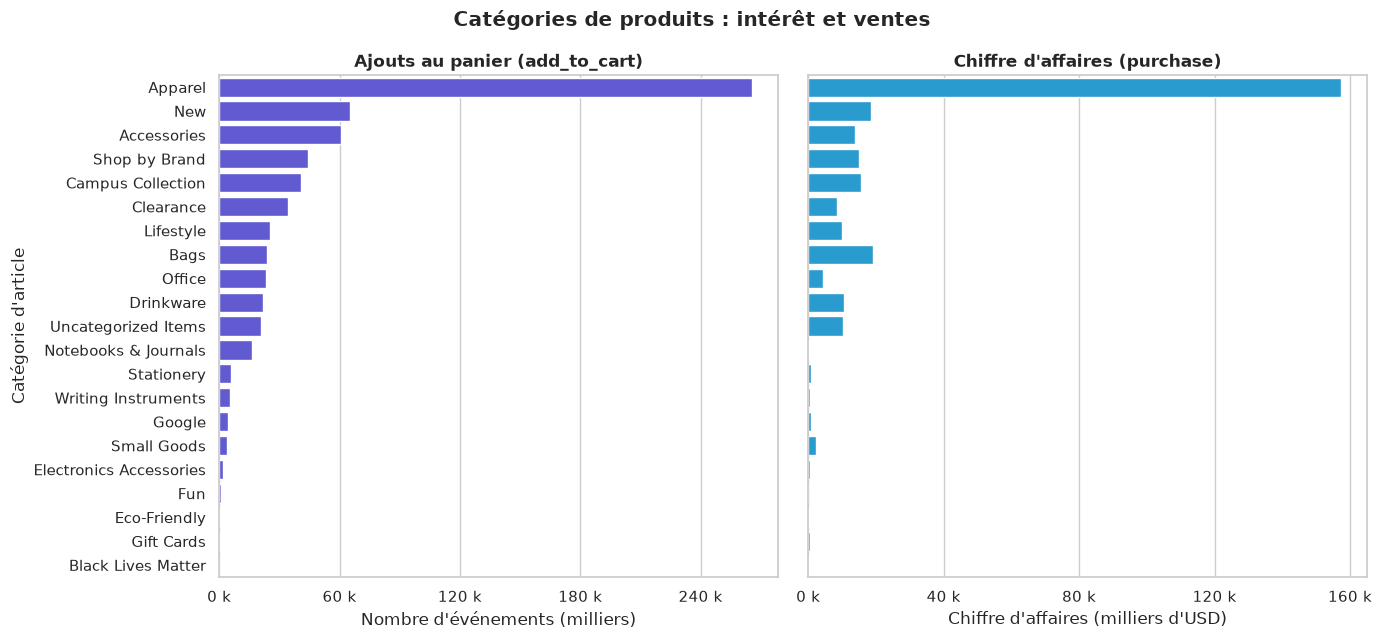

In [40]:
donnees_categories = repartition_categories.reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)
sns.barplot(data=donnees_categories, y="item_category", x="ajouts_panier", ax=axes[0], color="#4F46E5")
axes[0].set_title("Ajouts au panier (add_to_cart)")
axes[0].set_xlabel("Nombre d'événements (milliers)")
axes[0].set_ylabel("Catégorie d'article")

sns.barplot(data=donnees_categories, y="item_category", x="ca_usd", ax=axes[1], color="#0EA5E9")
axes[1].set_title("Chiffre d'affaires (purchase)")
axes[1].set_xlabel("Chiffre d'affaires (milliers d'USD)")
axes[1].set_ylabel("")
for axe in axes:
    axe.xaxis.set_major_locator(plt.MaxNLocator(5))
    axe.xaxis.set_major_formatter(FORMAT_KILO)
fig.suptitle("Catégories de produits : intérêt et ventes", fontweight="bold")
fig.tight_layout()
enregistrer(fig, "categories.png")
plt.show()

In [41]:
# Pourquoi Bags vend-il plus que son volume d'ajouts au panier ne le laisse prévoir ?
colonnes = ["ajouts_panier", "achats", "ca_usd", "achats_pour_100_ajouts", "prix_moyen_achat_usd"]
repartition_categories.loc[["Apparel", "Bags", "New", "Office", "Notebooks & Journals"], colonnes].round(2)

,ajouts_panier,achats,ca_usd,achats_pour_100_ajouts,prix_moyen_achat_usd
item_category,,,,,
Apparel,265434,4858,157235.0,1.83,32.37
Bags,23851,671,19137.0,2.81,28.52
New,65046,1397,18506.0,2.15,13.25
Office,23343,798,4501.0,3.42,5.64
Notebooks & Journals,16514,36,246.0,0.22,6.83


**Interprétation.**
- `Apparel` écrase les autres catégories : **265 434 ajouts au panier** et **157 235 USD** de chiffre d'affaires, soit **54,3 %** des ventes.
- L'intérêt ne se traduit pas toujours en ventes : `Bags` n'est que 8e en ajouts au panier (23 851) mais **2e en chiffre d'affaires (19 137 USD)**. Ce n'est pas une question de prix (28,52 USD en moyenne par achat, contre 32,37 USD pour `Apparel`) : l'écart vient surtout d'une **meilleure transformation des ajouts en achats**, avec 2,81 achats pour 100 ajouts au panier contre 1,83 pour `Apparel`. À l'inverse, `Notebooks & Journals` cumule **16 514 ajouts au panier pour seulement 36 achats (246 USD)**, soit 0,22 achat pour 100 ajouts : une catégorie très « regardée » mais presque jamais achetée.
- Les catégories marginales (`Fun`, `Eco-Friendly`, `Gift Cards`, `Black Lives Matter`) totalisent moins de 1 % des événements.

### 10.3 Engagement par appareil : distribution de la durée de session

La durée de session est **très asymétrique** (médiane de quelques dizaines de secondes, maximum de plusieurs heures) : sur une échelle linéaire, presque toutes les sessions seraient écrasées contre zéro. On utilise donc une **échelle logarithmique**, qui exige des valeurs strictement positives : les sessions de durée nulle (un seul horodatage) sont **chiffrées à part** ci-dessous puis exclues de ces deux graphiques uniquement.

Sessions de durée nulle : 5 922 (32,7 %)
device
desktop    0.330
mobile     0.323
tablet     0.333


Figure enregistrée : rapport/figures/engagement_appareil.png


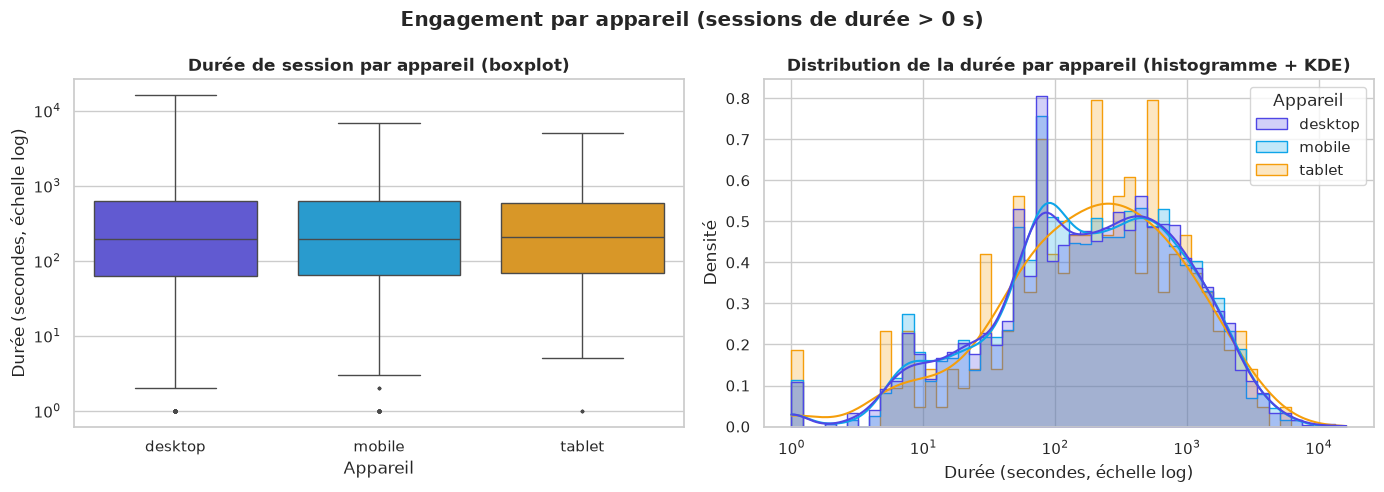

In [42]:
part_duree_nulle = sessions.groupby("device")["duration_s"].apply(lambda d: (d == 0).mean()).reindex(ORDRE_APPAREILS)
print(f"Sessions de durée nulle : {nombre_fr((sessions['duration_s'] == 0).sum())} ({pct_fr((sessions['duration_s'] == 0).mean())})")
print(part_duree_nulle.round(3).to_string())

sessions_positives = sessions[sessions["duration_s"] > 0]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=sessions_positives, x="device", y="duration_s", hue="device", order=ORDRE_APPAREILS,
            palette=COULEURS_APPAREILS, log_scale=True, fliersize=1.5, ax=axes[0])
axes[0].set_title("Durée de session par appareil (boxplot)")
axes[0].set_xlabel("Appareil")
axes[0].set_ylabel("Durée (secondes, échelle log)")

sns.histplot(data=sessions_positives, x="duration_s", hue="device", hue_order=ORDRE_APPAREILS,
             palette=COULEURS_APPAREILS, log_scale=True, kde=True, stat="density", common_norm=False,
             element="step", alpha=0.25, ax=axes[1])
axes[1].set_title("Distribution de la durée par appareil (histogramme + KDE)")
axes[1].set_xlabel("Durée (secondes, échelle log)")
axes[1].set_ylabel("Densité")
axes[1].get_legend().set_title("Appareil")
fig.suptitle("Engagement par appareil (sessions de durée > 0 s)", fontweight="bold")
fig.tight_layout()
enregistrer(fig, "engagement_appareil.png")
plt.show()

In [43]:
sessions_positives.groupby("device")["duration_s"].describe(percentiles=[0.25, 0.5, 0.75]).reindex(ORDRE_APPAREILS).round(0)

,count,mean,std,min,25%,50%,75%,max
device,,,,,,,,
desktop,7027.0,513.0,835.0,1.0,62.0,197.0,627.0,16196.0
mobile,4898.0,501.0,760.0,1.0,65.0,196.0,620.0,6895.0
tablet,254.0,487.0,714.0,1.0,70.0,208.0,580.0,5088.0


**Interprétation.**
- **5 922 sessions (32,7 %)** ont une durée nulle (un seul horodatage), dans les mêmes proportions sur les trois appareils (33,0 % desktop, 32,3 % mobile, 33,3 % tablet) ; elles sont exclues des deux graphiques à cause de l'échelle logarithmique, mais restent dans les données et les KPI.
- Pour les sessions de durée positive, les distributions sont **presque superposées** : médiane de **197 s** sur desktop, **196 s** sur mobile et **208 s** sur tablet ; troisième quartile de 580 à 627 s. La seule différence visible est l'extrême de la queue : jusqu'à 16 196 s sur desktop contre 6 895 s sur mobile.
- La courbe KDE montre une forme **bimodale** : un premier mode vers 80 s (visites éclairs, un ou deux ajouts au panier) et un second, plus large, entre 200 et 1 000 s (sessions de composition de panier).
- Conclusion : **l'appareil ne différencie pas l'engagement** dans ce jeu. L'histogramme de la tablette est plus irrégulier car il ne repose que sur 254 sessions.
- Le complément `sns.kdeplot` sur la valeur du panier confirme cette homogénéité : panier médian identique de 382 USD sur les trois appareils, valeur qui reflète l'artefact des paniers de 12 articles signalé plus haut.

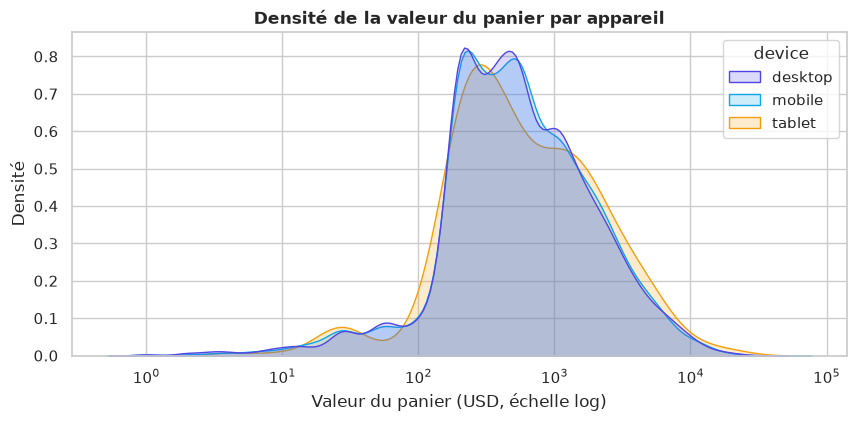

device
desktop    382.0
mobile     382.0
tablet     382.0


In [44]:
# Complément : densité (sns.kdeplot) de la valeur du panier par appareil, sessions avec panier > 0
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.kdeplot(data=sessions[sessions["cart_value_usd"] > 0], x="cart_value_usd", hue="device",
            hue_order=ORDRE_APPAREILS, palette=COULEURS_APPAREILS, log_scale=True, common_norm=False,
            fill=True, alpha=0.2, ax=ax)
plt.title("Densité de la valeur du panier par appareil")
plt.xlabel("Valeur du panier (USD, échelle log)")
plt.ylabel("Densité")
plt.grid(True)
plt.show()
print(sessions.groupby("device")["cart_value_usd"].median().reindex(ORDRE_APPAREILS).rename("panier médian (USD)").to_string())

### 10.4 Heatmap heure x jour de la semaine

Nombre de sessions selon l'heure et le jour de **début** de session, jours ordonnés du lundi au dimanche (libellés français pour l'affichage, codes `weekday` 0 à 6 dans les données). La grille est complétée à 7 x 24 cases (zéro si aucune session).

Figure enregistrée : rapport/figures/heatmap_heure_jour.png


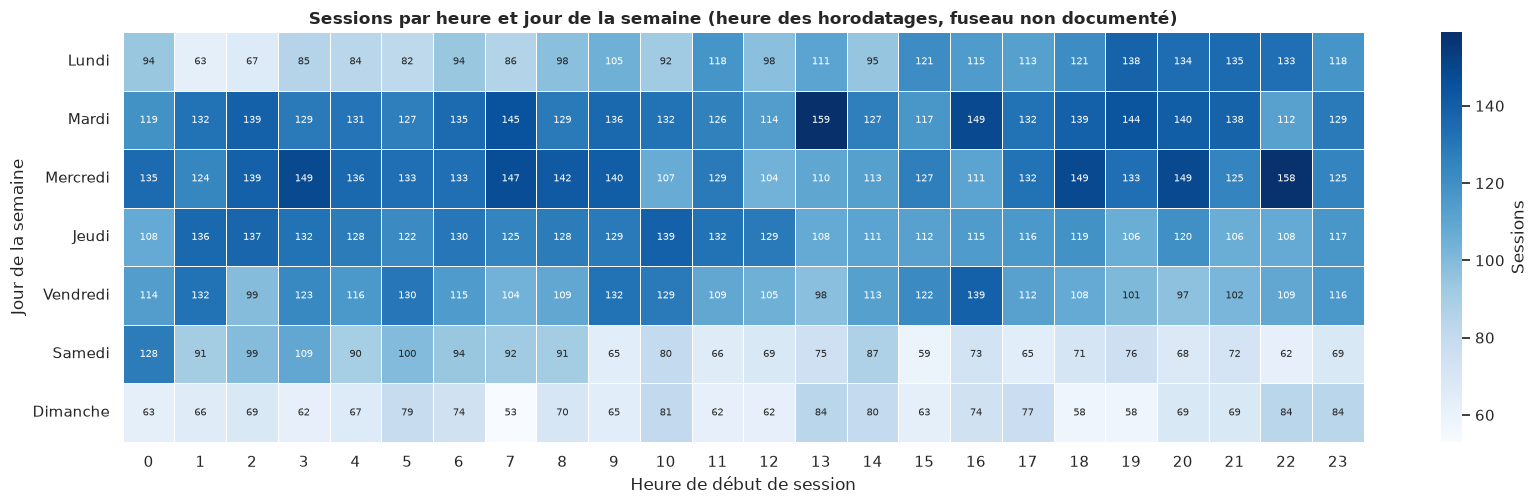

In [45]:
grille = (sessions.pivot_table(index="weekday", columns="hour", values="session_key", aggfunc="count")
          .reindex(index=range(7), columns=range(24)).fillna(0).astype(int))
grille.index = JOURS_FR

fig, ax = plt.subplots(figsize=(17, 5.2))
# Palette séquentielle (une seule teinte) : adaptée à des effectifs, du clair (peu) au foncé (beaucoup)
sns.heatmap(grille, annot=True, fmt="d", cmap="Blues", annot_kws={"size": 7.5},
            linewidths=0.4, linecolor="white", cbar_kws={"label": "Sessions"}, ax=ax)
plt.title("Sessions par heure et jour de la semaine (heure des horodatages, fuseau non documenté)")
plt.xlabel("Heure de début de session")
plt.ylabel("Jour de la semaine")
plt.yticks(rotation=0)
fig.tight_layout()
enregistrer(fig, "heatmap_heure_jour.png")
plt.show()

In [46]:
par_heure = grille.sum(axis=0)
par_jour = grille.sum(axis=1)
print("Heures les plus actives :", par_heure.sort_values(ascending=False).head(3).to_dict())
print("Heures les plus creuses :", par_heure.sort_values().head(3).to_dict())
print("Sessions par jour de semaine :", par_jour.to_dict())
print(f"Case maximale : {grille.stack().idxmax()} ({grille.values.max()} sessions)")

Heures les plus actives : {3: 789, 20: 777, 16: 776}
Heures les plus creuses : {12: 681, 15: 721, 14: 726}
Sessions par jour de semaine : {'Lundi': 2500, 'Mardi': 3180, 'Mercredi': 3150, 'Jeudi': 2913, 'Vendredi': 2734, 'Samedi': 1951, 'Dimanche': 1673}
Case maximale : ('Mardi', 13) (159 sessions)


**Interprétation.**
- **Le jour de la semaine structure fortement le trafic** : les mardis (**3 180** sessions) et mercredis (3 150) sont les plus actifs, le week-end le plus creux (samedi 1 951, dimanche **1 673**), soit près de deux fois moins de sessions le dimanche que le mardi. Les deux lignes du week-end sont les plus claires à presque toutes les heures : on achète ces produits dérivés surtout en semaine, profil compatible avec des achats de bureau ou d'entreprise.
- **L'heure, en revanche, discrimine très peu** : le total par heure ne varie que de **681 sessions (12 h)** à **789 (3 h)**, sans cycle jour / nuit marqué. La case la plus foncée est le mardi à 13 h (159 sessions).
- Cette absence de creux nocturne est surprenante pour une audience à 44 % américaine : elle s'explique soit par la diversité des fuseaux des visiteurs, soit par l'obfuscation des horodatages de l'échantillon public. Les analyses horaires sont donc à lire avec prudence (voir la limite ci-dessous).

**Limite : fuseau horaire.** La source ne documente pas le fuseau horaire des horodatages. Il s'agit vraisemblablement de l'heure de la propriété Google Analytics (fuseau des États-Unis, la boutique étant américaine), et non de l'heure locale de chaque visiteur. Les analyses par heure doivent donc être lues comme des tendances relatives, en particulier pour les visiteurs hors d'Amérique du Nord.

### 10.5 Corrélations entre variables numériques de session

Figure enregistrée : rapport/figures/correlation.png


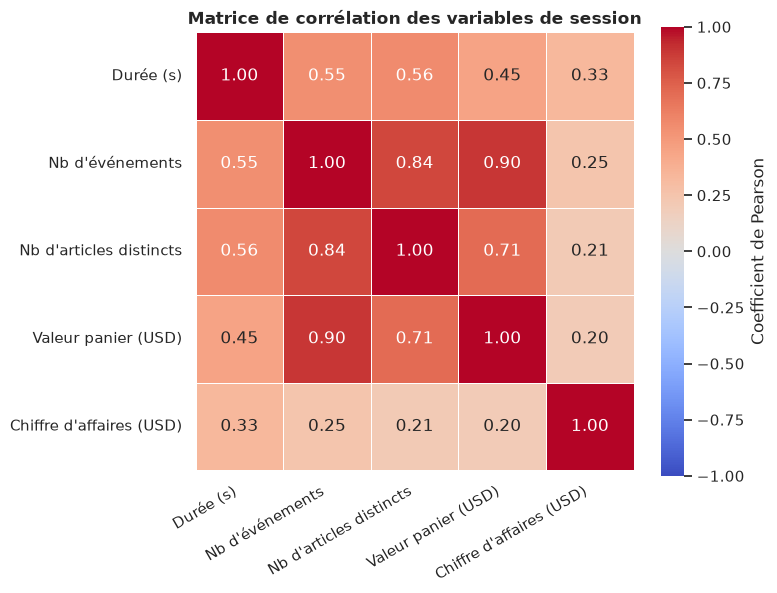

Spearman durée / événements : 0.71 | Pearson : 0.55


In [47]:
variables_numeriques = ["duration_s", "n_events", "n_items", "cart_value_usd", "revenue_usd"]
correlations = sessions[variables_numeriques].corr()
LIBELLES_VARIABLES = {"duration_s": "Durée (s)", "n_events": "Nb d'événements", "n_items": "Nb d'articles distincts",
                      "cart_value_usd": "Valeur panier (USD)", "revenue_usd": "Chiffre d'affaires (USD)"}

fig, ax = plt.subplots(figsize=(7.8, 6.2))
sns.heatmap(correlations.rename(index=LIBELLES_VARIABLES, columns=LIBELLES_VARIABLES), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"label": "Coefficient de Pearson"}, ax=ax)
plt.title("Matrice de corrélation des variables de session")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
fig.tight_layout()
enregistrer(fig, "correlation.png")
plt.show()
# Corrélation de Spearman = corrélation de Pearson calculée sur les rangs (robuste aux valeurs extrêmes)
spearman = sessions[variables_numeriques].rank().corr()
print("Spearman durée / événements :", round(spearman.loc["duration_s", "n_events"], 2),
      "| Pearson :", round(correlations.loc["duration_s", "n_events"], 2))

**Interprétation.**
- **`n_events` et `cart_value_usd` : 0,90**. Corrélation en partie mécanique : 92,6 % des événements sont des `add_to_cart`, donc plus d'événements signifie presque toujours un panier plus cher. De même `n_events` et `n_items` (0,84).
- **Durée et nombre d'événements : 0,55** en Pearson, mais **0,71** en Spearman (corrélation de rangs) : la relation est nettement croissante mais non linéaire, et le coefficient de Pearson est affaibli par les valeurs extrêmes.
- **Le chiffre d'affaires est faiblement corrélé à tout le reste** (0,20 à 0,33) : une session longue et chargée ne garantit pas un achat. La durée est la variable la plus liée au chiffre d'affaires (0,33), devant le nombre d'événements (0,25).

### 10.6 Entonnoir de conversion

Part des sessions atteignant chaque étape (une session compte pour une étape si elle contient au moins un événement de ce type), globalement et par appareil.

In [48]:
ETAPES = ["add_to_cart", "begin_checkout", "purchase"]
presence = (events.groupby(["session_key", "type"]).size().unstack(fill_value=0) > 0)[ETAPES]
presence = presence.join(sessions.set_index("session_key")["device"])

entonnoir = presence[ETAPES].sum().rename("sessions").to_frame()
entonnoir["part des sessions"] = entonnoir["sessions"] / len(sessions)
# Simple rapport des effectifs d'une étape à la précédente (n'est PAS une probabilité de passage,
# car toutes les sessions d'une étape ne sont pas passées par l'étape précédente)
entonnoir["ratio des effectifs"] = entonnoir["sessions"] / entonnoir["sessions"].shift(1)
# Taux conditionnel : parmi les sessions ayant atteint l'étape précédente, part atteignant celle-ci
panier, paiement, achat = presence["add_to_cart"], presence["begin_checkout"], presence["purchase"]
entonnoir["taux conditionnel"] = [np.nan, (panier & paiement).sum() / panier.sum(),
                                  (paiement & achat).sum() / paiement.sum()]
entonnoir_appareils = presence.groupby("device")[ETAPES].mean().reindex(ORDRE_APPAREILS)
display(entonnoir.round(3))

print(f"P(begin_checkout | add_to_cart) = {pct_fr(entonnoir.loc['begin_checkout', 'taux conditionnel'])}")
print(f"P(purchase | begin_checkout)    = {pct_fr(entonnoir.loc['purchase', 'taux conditionnel'])}")
print(f"P(purchase | add_to_cart)       = {pct_fr((panier & achat).sum() / panier.sum())}")
print("Sessions sans add_to_cart :", (~panier).sum())
print("Sessions avec begin_checkout mais sans add_to_cart :", (paiement & ~panier).sum())
print("Sessions avec purchase mais sans begin_checkout :", (achat & ~paiement).sum())
print("Sessions avec purchase mais sans add_to_cart :", (achat & ~panier).sum())
print("Sessions passant par les trois étapes :", (panier & paiement & achat).sum())
entonnoir_appareils.round(3)

,sessions,part des sessions,ratio des effectifs,taux conditionnel
add_to_cart,15188,0.839,NaN,NaN
begin_checkout,7308,0.404,0.481,0.350
purchase,4446,0.246,0.608,0.471


P(begin_checkout | add_to_cart) = 35,0 %
P(purchase | begin_checkout)    = 47,1 %
P(purchase | add_to_cart)       = 16,9 %
Sessions sans add_to_cart : 2913
Sessions avec begin_checkout mais sans add_to_cart : 1993
Sessions avec purchase mais sans begin_checkout : 1006
Sessions avec purchase mais sans add_to_cart : 1873
Sessions passant par les trois étapes : 2487


,add_to_cart,begin_checkout,purchase
device,,,
desktop,0.838,0.405,0.241
mobile,0.840,0.402,0.252
tablet,0.843,0.417,0.239


Figure enregistrée : rapport/figures/entonnoir.png


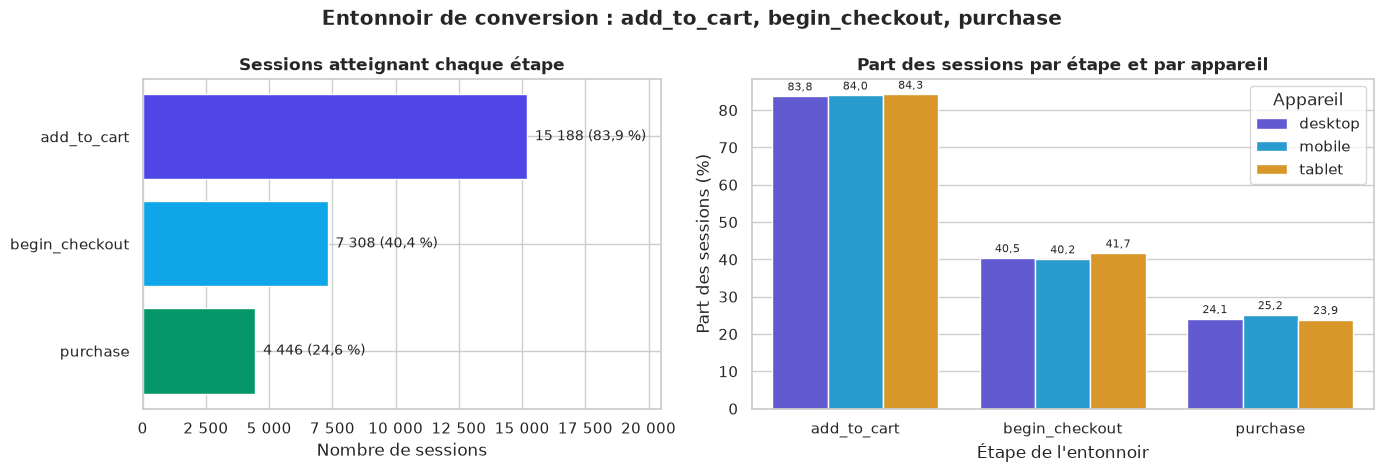

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.2]})
couleurs_etapes = ["#4F46E5", "#0EA5E9", "#059669"]
axes[0].barh(ETAPES[::-1], entonnoir["sessions"][::-1], color=couleurs_etapes[::-1])
for position, etape in enumerate(ETAPES[::-1]):
    valeur = entonnoir.loc[etape, "sessions"]
    part = entonnoir.loc[etape, "part des sessions"]
    axes[0].text(valeur, position, f"  {nombre_fr(valeur)} ({nombre_fr(part * 100, 1)} %)", va="center", fontsize=10)
axes[0].set_xlim(0, entonnoir["sessions"].max() * 1.35)
axes[0].xaxis.set_major_formatter(FORMAT_MILLIERS)
axes[0].set_title("Sessions atteignant chaque étape")
axes[0].set_xlabel("Nombre de sessions")

donnees_entonnoir = (entonnoir_appareils * 100).reset_index().melt(id_vars="device", var_name="étape",
                                                                     value_name="part")
sns.barplot(data=donnees_entonnoir, x="étape", y="part", hue="device", hue_order=ORDRE_APPAREILS,
            palette=COULEURS_APPAREILS, ax=axes[1])
for conteneur in axes[1].containers:
    axes[1].bar_label(conteneur, labels=[nombre_fr(b.get_height(), 1) for b in conteneur], fontsize=8, padding=2)
axes[1].set_title("Part des sessions par étape et par appareil")
axes[1].set_xlabel("Étape de l'entonnoir")
axes[1].set_ylabel("Part des sessions (%)")
axes[1].legend(title="Appareil")
fig.suptitle("Entonnoir de conversion : add_to_cart, begin_checkout, purchase", fontweight="bold")
fig.tight_layout()
enregistrer(fig, "entonnoir.png")
plt.show()

**Interprétation.**
- **15 188 sessions (83,9 %)** contiennent un ajout au panier, **7 308 (40,4 %)** un début de paiement et **4 446 (24,6 %)** un achat.
- L'entonnoir n'est **pas un chemin strict** : **2 913 sessions n'ont aucun `add_to_cart`**, dont **1 993** qui commencent pourtant un paiement, et **1 006 sessions achètent sans `begin_checkout`** enregistré dans la même session. Une hypothèse plausible est que le panier a été constitué lors d'une visite précédente (ou que certains événements n'ont pas été transmis) ; les données ne permettent pas de le vérifier.
- Le simple rapport des effectifs d'une étape à l'autre (7 308 / 15 188 puis 4 446 / 7 308) n'est donc **pas** une probabilité de passage. Les **taux conditionnels**, calculés sur les mêmes sessions, sont plus bas : **35,0 %** des sessions avec ajout au panier commencent un paiement, et **47,1 %** des sessions avec début de paiement achètent. Parmi les sessions avec ajout au panier, 16,9 % aboutissent à un achat dans la même session.
- **La plus grosse perte se situe donc entre le panier et le paiement** (65,0 % des sessions avec panier s'arrêtent là, contre 52,9 % entre paiement et achat). C'est le panier, plus encore que le tunnel de paiement, qu'il faut travailler.
- L'entonnoir est **identique selon l'appareil** (achat : 24,1 % desktop, 25,2 % mobile, 23,9 % tablet), ce qui confirme les conclusions sur l'engagement.
- Définition retenue, reprise par l'application : l'entonnoir mesure la **présence** de chaque étape dans une session.

## 11. Export des données traitées

Les deux tables sont exportées en **Parquet** (compression snappy) : format colonne, typé (les `datetime` et booléens sont conservés, contrairement au CSV) et beaucoup plus léger, ce qui accélère le chargement de l'application en ligne. Avant l'export, on vérifie qu'aucun texte ne contient le caractère cadratin interdit.

In [50]:
COLONNES_SESSIONS = ["session_key", "user_id", "ga_session_id", "country", "country_iso3", "country_name",
                     "device", "start", "end", "date", "hour", "weekday", "duration_s", "n_events", "n_items",
                     "cart_value_usd", "revenue_usd", "reached_checkout", "purchased", "main_category",
                     "is_outlier_duration", "is_outlier_events"]
sessions = sessions[COLONNES_SESSIONS].sort_values("start").reset_index(drop=True)

for nom, table in [("events", events), ("sessions", sessions)]:
    textes = table.select_dtypes(include=["object", "string"])
    assert not textes.apply(lambda c: c.astype(str).str.contains(CADRATIN, regex=False).any()).any(), nom

events.to_parquet(DOSSIER_TRAITE / "events_clean.parquet", index=False, compression="snappy")
sessions.to_parquet(DOSSIER_TRAITE / "sessions.parquet", index=False, compression="snappy")

for fichier in ["events_clean.parquet", "sessions.parquet"]:
    taille = (DOSSIER_TRAITE / fichier).stat().st_size / 1024 ** 2
    print(f"data/processed/{fichier:<22} {nombre_fr(taille, 1):>5} Mo")
taille_brute = sum((DOSSIER_BRUT / f).stat().st_size for f in ["events.csv", "items.csv"]) / 1024 ** 2
print(f"Pour comparaison, events.csv + items.csv bruts : {nombre_fr(taille_brute, 1)} Mo")

data/processed/events_clean.parquet     3,9 Mo
data/processed/sessions.parquet         0,9 Mo
Pour comparaison, events.csv + items.csv bruts : 41,7 Mo


In [51]:
# Relecture : les types sont bien conservés par le format Parquet
relu = pd.read_parquet(DOSSIER_TRAITE / "sessions.parquet")
print(relu.dtypes.to_string())

session_key                       str
user_id                         int64
ga_session_id                   int64
country                           str
country_iso3                      str
country_name                      str
device                            str
start                  datetime64[ns]
end                    datetime64[ns]
date                   datetime64[ns]
hour                            int64
weekday                         int64
duration_s                    float64
n_events                        int64
n_items                         int64
cart_value_usd                float64
revenue_usd                   float64
reached_checkout                 bool
purchased                        bool
main_category                     str
is_outlier_duration              bool
is_outlier_events                bool


## 12. Bilan du pré-traitement

In [52]:
bilan = pd.DataFrame({
    "étape": ["Lecture de events.csv", "Valeurs manquantes de country", "Suppression des doublons exacts",
              "Jointure items + pycountry", "Agrégation en sessions", "Sessions signalées aberrantes (durée)",
              "Sessions signalées aberrantes (événements)"],
    "résultat": [f"{nombre_fr(n_avant)} événements",
                 f"{nombre_fr(events_brut['country'].isna().sum())} remplacées par '(not set)'",
                 f"-{nombre_fr(n_avant - n_apres)} lignes, {nombre_fr(n_apres)} restantes",
                 f"{nombre_fr(len(events))} lignes (aucune perte)",
                 f"{nombre_fr(len(sessions))} sessions, {nombre_fr(sessions['user_id'].nunique())} utilisateurs",
                 f"{nombre_fr(sessions['is_outlier_duration'].sum())} (conservées, indicateur)",
                 f"{nombre_fr(sessions['is_outlier_events'].sum())} (conservées, indicateur)"],
})
bilan.set_index("étape")

,résultat
étape,
Lecture de events.csv,758 884 événements
Valeurs manquantes de country,4 555 remplacées par '(not set)'
Suppression des doublons exacts,"-39 498 lignes, 719 386 restantes"
Jointure items + pycountry,719 386 lignes (aucune perte)
Agrégation en sessions,"18 101 sessions, 14 701 utilisateurs"
Sessions signalées aberrantes (durée),"2 075 (conservées, indicateur)"
Sessions signalées aberrantes (événements),"1 901 (conservées, indicateur)"


## Conclusion

Le pré-traitement transforme **758 884 événements bruts** en **719 386 événements propres** (39 498 doublons exacts supprimés, 4 555 pays manquants explicités en `(not set)`, jointure catalogue et pays sans perte), puis en **18 101 sessions** décrites par 22 variables. Aucune session n'est supprimée : les **2 075** sessions longues et les **1 901** sessions très actives sont signalées par un indicateur, car elles portent 42,4 % du chiffre d'affaires.

Les deux fichiers Parquet (environ **3,9 Mo** pour les événements et **0,9 Mo** pour les sessions, contre 41,7 Mo de CSV bruts) alimentent l'application Streamlit ; les figures de `rapport/figures/` illustrent le rapport.

**Constats principaux** : une saisonnalité très forte (pic du 1er au 11 décembre, record le 8 décembre), un trafic de semaine, un engagement et une conversion indépendants de l'appareil, `Apparel` majoritaire, et une perte principale entre panier et paiement (35,0 % seulement des sessions avec ajout au panier commencent un paiement).

**Limites** :
- fuseau horaire des horodatages non documenté (probablement celui de la propriété Google Analytics, aux États-Unis) et profil horaire anormalement plat ;
- échantillon **obfusqué** par Google : identifiants anonymisés et motifs artificiels (34,0 % des sessions à exactement 12 articles) ;
- **32,7 %** de sessions de durée nulle (un seul horodatage), dont la durée réelle est inconnue ;
- le jeu ne contient que des événements e-commerce (pas de pages vues) : une « session » est ici une visite ayant au moins une action panier, paiement ou achat.